<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.6_regressao_linear_salarios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 2.6 — Regressão linear com dados reais: salários (treino × validação)

## Objetivos

- Aplicar o pipeline do 2.5 (`nn.Linear`, `nn.MSELoss`, `optim.SGD`) a um dataset real: salário em função dos anos de experiência.
- Separar os dados em treino e validação (70/30) e acompanhar a função de custo (loss) nos dois conjuntos.
- Organizar o treino em funções `train_epoch` e `validate_epoch`, com `model.train()`, `model.eval()` e `torch.no_grad()`.
- Usar o bias da própria camada (`nn.Linear(1, 1)`) no lugar da coluna de uns.

O problema é o exemplo dos slides: dado o tempo de experiência de um profissional, prever o seu salário. A entrada $x$ é `YearsExperience` (anos de experiência) e a saída $y$ é `Salary` (salário anual; a fonte não informa a moeda). O modelo é a mesma reta dos notebooks anteriores:

$$\hat{y} = w_0 + w_1 x$$

com $w_0$ = bias (intercepto) e $w_1$ = peso. Nos slides: $h_\theta(x) = \theta_0 + \theta_1 x$, com $w_0 = \theta_0$ e $w_1 = \theta_1$.

O que muda em relação ao 2.5: os dados são reais e poucos (30 profissionais), parte deles é separada para validação, e o bias passa a ser um parâmetro da camada.

## Importação das bibliotecas

In [1]:
import io
import pathlib
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

### Download

Fonte: [Salary Dataset - Simple linear regression](https://www.kaggle.com/datasets/abhishek14398/salary-dataset-simple-linear-regression) (Kaggle). O endpoint público de download do Kaggle entrega o `.zip` sem login. O arquivo `Salary_dataset.csv` tem uma coluna de índice sem nome, `YearsExperience` e `Salary`.

Ele é uma cópia do clássico `Salary_Data.csv`, com 0,1 ano e 1 unidade de salário somados a todas as linhas. Se o Kaggle estiver indisponível, a célula baixa o `Salary_Data.csv` de um repositório público no GitHub. Depois da padronização (abaixo), os dois arquivos dão os mesmos valores, porque somar uma constante não muda a padronização.

O arquivo vai para a pasta `./data`; se já existir, não é baixado de novo.

In [2]:
DATA_DIR = pathlib.Path('data')
DATA_DIR.mkdir(exist_ok=True)

KAGGLE_URL = 'https://www.kaggle.com/api/v1/datasets/download/abhishek14398/salary-dataset-simple-linear-regression'
MIRROR_URL = 'https://raw.githubusercontent.com/krishnaik06/simple-Linear-Regression/master/Salary_Data.csv'

csv_path = DATA_DIR / 'Salary_dataset.csv'
if not csv_path.exists():
    try:
        with urllib.request.urlopen(KAGGLE_URL, timeout=30) as resp:
            zipfile.ZipFile(io.BytesIO(resp.read())).extract('Salary_dataset.csv', DATA_DIR)
        print('baixado do Kaggle:', csv_path)
    except Exception as e:
        print('Kaggle indisponível (', e, '); usando a cópia do GitHub')
        csv_path = DATA_DIR / 'Salary_Data.csv'
        urllib.request.urlretrieve(MIRROR_URL, csv_path)
print('arquivo:', csv_path)

baixado do Kaggle: data/Salary_dataset.csv
arquivo: data/Salary_dataset.csv


### Leitura

In [3]:
df = pd.read_csv(csv_path)
df = df[['YearsExperience', 'Salary']]   # descarta a coluna de índice, se houver
print('shape:', df.shape)
df.head()

shape: (30, 2)


,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


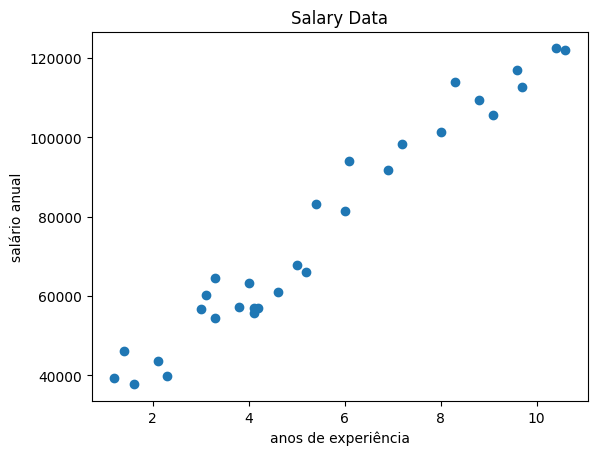

In [4]:
plt.scatter(df['YearsExperience'], df['Salary'])
plt.xlabel('anos de experiência')
plt.ylabel('salário anual')
plt.title('Salary Data')
plt.show()

### Treino × validação

Os parâmetros são ajustados só com o conjunto de treino. O conjunto de validação fica de fora do treino e serve para medir o custo em dados que o modelo não viu: um custo baixo no treino não garante um custo baixo em dados novos.

`train_test_split(..., test_size=0.3, random_state=42)` sorteia 30% das linhas para validação: 21 amostras de treino e 9 de validação. `random_state` fixa o sorteio, para que a divisão seja sempre a mesma. Com só 30 amostras, não separamos um terceiro conjunto (teste).

In [5]:
x_raw = df[['YearsExperience']].to_numpy()   # (30, 1)
y_raw = df[['Salary']].to_numpy()            # (30, 1)

x_train_raw, x_val_raw, y_train_raw, y_val_raw = train_test_split(
    x_raw, y_raw, test_size=0.3, random_state=42)
print('treino:', x_train_raw.shape, ' validação:', x_val_raw.shape)

treino: (21, 1)  validação: (9, 1)


### Normalização

Anos de experiência ficam entre 1 e 11; salários, entre ~37 mil e ~122 mil. Com escalas tão diferentes, o gradiente descendente precisaria de uma taxa de aprendizado minúscula. Padronizamos cada variável (z-score):

$$z = \frac{x - \mu}{\sigma}$$

em que $\mu$ e $\sigma$ são a média e o desvio padrão. O `StandardScaler` do scikit-learn faz essa conta: `fit` calcula $\mu$ e $\sigma$, `transform` aplica a fórmula e `inverse_transform` desfaz.

$\mu$ e $\sigma$ são calculados **só no treino** e depois aplicados à validação. Se fossem calculados com todos os dados, informação da validação entraria no treino (vazamento de dados), e a validação deixaria de representar dados novos.

In [6]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

# tensores float32 (sem requires_grad: são dados, não parâmetros)
x_train = torch.from_numpy(x_scaler.transform(x_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()
x_val = torch.from_numpy(x_scaler.transform(x_val_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('x_val:  ', x_val.shape, ' y_val:  ', y_val.shape)

x_train: torch.Size([21, 1])  y_train: torch.Size([21, 1])
x_val:   torch.Size([9, 1])  y_val:   torch.Size([9, 1])


## Modelo

`nn.Linear(1, 1)` tem `bias=True` por padrão e calcula $\hat{y} = w_1 x + w_0$:

- `model.weight`, shape (1, 1), é o peso $w_1$;
- `model.bias`, shape (1,), é o bias $w_0$.

São os mesmos 2 parâmetros dos notebooks anteriores, mas agora não é preciso a coluna de uns (`x_train_bias`): a camada soma o bias. Usamos a inicialização padrão do `nn.Linear`.

In [7]:
model = nn.Linear(1, 1)
print('weight (w1):', model.weight)
print('bias (w0):  ', model.bias)

weight (w1): Parameter containing:
tensor([[-0.9420]], requires_grad=True)
bias (w0):   Parameter containing:
tensor([-0.1962], requires_grad=True)


### Testando o predict da rede

In [8]:
model(torch.ones(5, 1))

tensor([[-1.1382],
        [-1.1382],
        [-1.1382],
        [-1.1382],
        [-1.1382]], grad_fn=<AddmmBackward0>)

In [9]:
model(x_train[:3])

tensor([[ 1.0913],
        [ 0.7119],
        [-0.2882]], grad_fn=<AddmmBackward0>)

## Treinamento

### Função de custo e otimizador

Os mesmos do 2.5.

In [10]:
lr = 0.3
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)   # atualiza weight e bias

### Funções de treino e de validação

O código de uma época vira duas funções:

- `train_epoch` faz um passo de gradiente descendente com todo o conjunto de treino (as 21 amostras de uma vez; aqui uma época é uma iteração. Mini-batches aparecem no 3.3) e devolve o custo;
- `validate_epoch` só calcula o custo na validação, sem atualizar nada.

Duas construções novas:

- `model.train()` e `model.eval()` colocam o modelo em modo de treino ou de avaliação. Para `nn.Linear` não muda nada; muda para camadas como dropout e batch normalization, que se comportam de forma diferente no treino (módulo 4). Usar os dois desde já é o padrão do PyTorch.
- `with torch.no_grad():` desliga o registro do grafo do autograd. Na validação não há `backward()`, então o grafo seria memória e tempo desperdiçados.

In [11]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()            # modo de treino
    optimizer.zero_grad()

    # forward
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    # backward e otimizador
    loss.backward()
    optimizer.step()

    return loss.item()       # custo como número Python

In [12]:
def validate_epoch(model, criterion, x_val, y_val):
    model.eval()             # modo de avaliação
    with torch.no_grad():    # sem grafo do autograd: não haverá backward
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

### Laço de treinamento

A cada época: um passo de treino, a medida na validação e o registro dos parâmetros. Observe que `train_loss` é medido no forward, antes do `step()` daquela época, e `val_loss` depois dele.

In [13]:
n_epochs = 120
w0_list = []   # bias
w1_list = []   # peso
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    w0_list.append(model.bias.item())
    w1_list.append(model.weight.item())

    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    train_losses.append(train_loss)

    val_loss = validate_epoch(model, criterion, x_val, y_val)
    val_losses.append(val_loss)

    if (epoch + 1) % 20 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')

Epoch[20/120], Train Loss: 0.042547, Val Loss: 0.055585
Epoch[40/120], Train Loss: 0.042547, Val Loss: 0.055585
Epoch[60/120], Train Loss: 0.042547, Val Loss: 0.055585
Epoch[80/120], Train Loss: 0.042547, Val Loss: 0.055585
Epoch[100/120], Train Loss: 0.042547, Val Loss: 0.055585
Epoch[120/120], Train Loss: 0.042547, Val Loss: 0.055585


## Avaliação

### Curvas de custo de treino e de validação

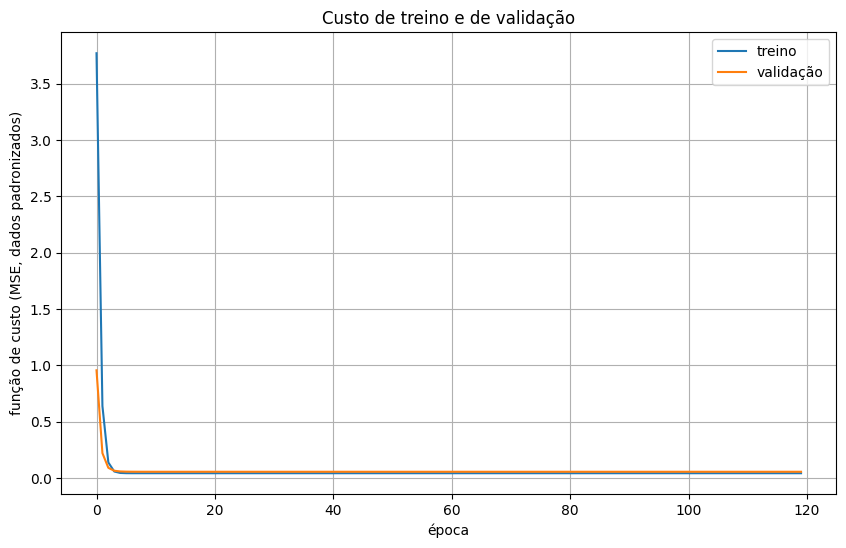

In [14]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

### Reta ajustada

A reta é calculada nos dados padronizados e levada de volta à escala original com `inverse_transform`, para ler os eixos em anos e em salário.

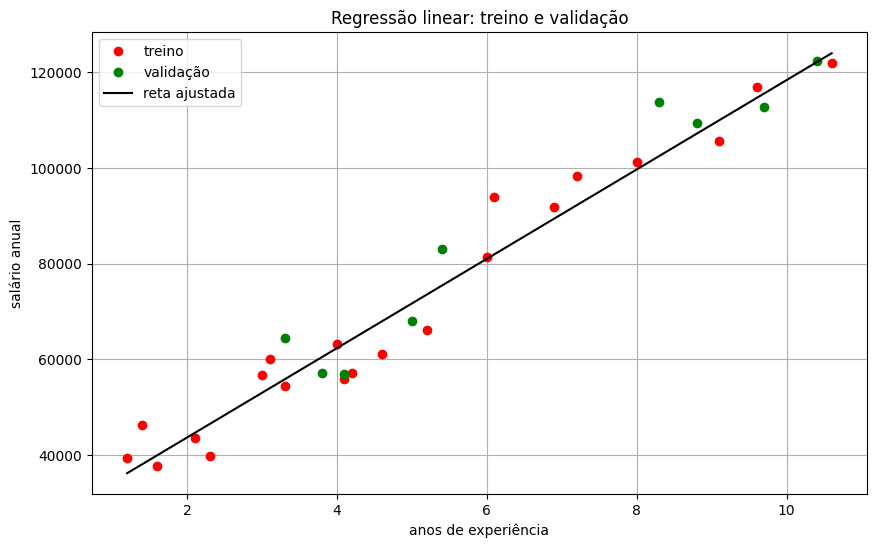

In [15]:
x_grid_raw = np.linspace(x_raw.min(), x_raw.max(), 100).reshape(-1, 1)
x_grid = torch.from_numpy(x_scaler.transform(x_grid_raw)).float()

model.eval()
with torch.no_grad():
    y_grid = model(x_grid)
y_grid_raw = y_scaler.inverse_transform(y_grid.numpy())

plt.figure(figsize=(10, 6))
plt.plot(x_train_raw, y_train_raw, 'ro', label='treino')
plt.plot(x_val_raw, y_val_raw, 'go', label='validação')
plt.plot(x_grid_raw, y_grid_raw, 'k-', label='reta ajustada')
plt.xlabel('anos de experiência')
plt.ylabel('salário anual')
plt.title('Regressão linear: treino e validação')
plt.legend()
plt.grid(True)
plt.show()

### Parâmetros treinados (na escala padronizada)

In [16]:
print('w0 (bias):', model.bias.item())
print('w1 (peso):', model.weight.item())
print(f'MSE final  treino: {train_losses[-1]:.4f}   validação: {val_losses[-1]:.4f}')

w0 (bias): -4.397277209022832e-09
w1 (peso): 0.9784950613975525
MSE final  treino: 0.0425   validação: 0.0556


## Exercícios

### Exercício 1 — Erro em unidades de salário

O MSE acima está na escala padronizada, difícil de interpretar. Calcule a raiz do erro quadrático médio (RMSE) na validação **em unidades de salário**:

$$\text{RMSE} = \sqrt{\frac{1}{M_{val}}\sum_{i=1}^{M_{val}}\left(\hat{y}^{(i)} - y^{(i)}\right)^2}$$

em que $M_{val} = 9$ é o número de amostras de validação. Use `y_scaler.inverse_transform` para levar as previsões de volta à escala original e compare com `y_val_raw`. Guarde o resultado em `rmse_val` e compare com o salário médio.

In [18]:
# Coloca o modelo em modo de avaliação e calcula as previsões
model.eval()
with torch.no_grad():
    y_pred_val = model(x_val).numpy()

# Desfaz a padronização das previsões para voltar à escala original (salários)
y_pred_val_raw = y_scaler.inverse_transform(y_pred_val)

# Calcula o RMSE (raiz do erro quadrático médio)
rmse_val = np.sqrt(np.mean((y_pred_val_raw - y_val_raw) ** 2))

print(f'RMSE de validação: {rmse_val:,.0f}')
print(f'salário médio:     {y_raw.mean():,.0f}')

RMSE de validação: 6,147
salário médio:     76,004


**Resposta:**


* O **RMSE de validação** obtido foi de **6.147 unidades de salário** (comparado a uma média salarial geral de **76.004**).
* Isso significa que, em média, as previsões do modelo desviam aproximadamente 6.147 da realidade no conjunto de dados que ele não viu durante o treinamento (cerca de 8,1% do salário médio).
* Considerando a simplicidade do modelo (uma regressão linear simples com apenas uma variável de entrada), esse erro é relativamente baixo e demonstra que a quantidade de anos de experiência é um preditor muito forte para estimar o salário.

### Exercício 2 — Previsão para um caso novo

Qual salário o modelo prevê para uma pessoa com 5 anos de experiência? Lembre-se de padronizar a entrada com `x_scaler` antes de passá-la ao modelo e de desfazer a padronização da saída. Guarde o valor (um número) em `salario_5`.

In [19]:
anos = np.array([[5.0]])

# Padroniza a entrada
anos_scaled = torch.from_numpy(x_scaler.transform(anos)).float()

# Faz a previsão com o modelo
model.eval()
with torch.no_grad():
    salario_pred_scaled = model(anos_scaled)

# Desfaz a padronização do salário previsto para obter o valor real
salario_5 = y_scaler.inverse_transform(salario_pred_scaled.numpy())[0, 0]

print(f'salário previsto para {anos[0, 0]:.0f} anos: {salario_5:,.0f}')

salário previsto para 5 anos: 71,681


### Exercício 3 — Taxa de aprendizado

Antes de executar, preveja: o que acontece com as curvas de validação se a taxa de aprendizado for 0,01? E 1,1?

Para cada `lr` em `[0.01, 0.1, 0.3, 1.1]`, crie um modelo novo (`torch.manual_seed(1234)` antes de `nn.Linear(1, 1)`, para todos partirem do mesmo ponto) e um otimizador novo, treine por `n_epochs` épocas com `train_epoch`/`validate_epoch` e plote as curvas de custo de validação no mesmo gráfico (use `plt.yscale('log')`). Qual valor você escolheria e por quê?

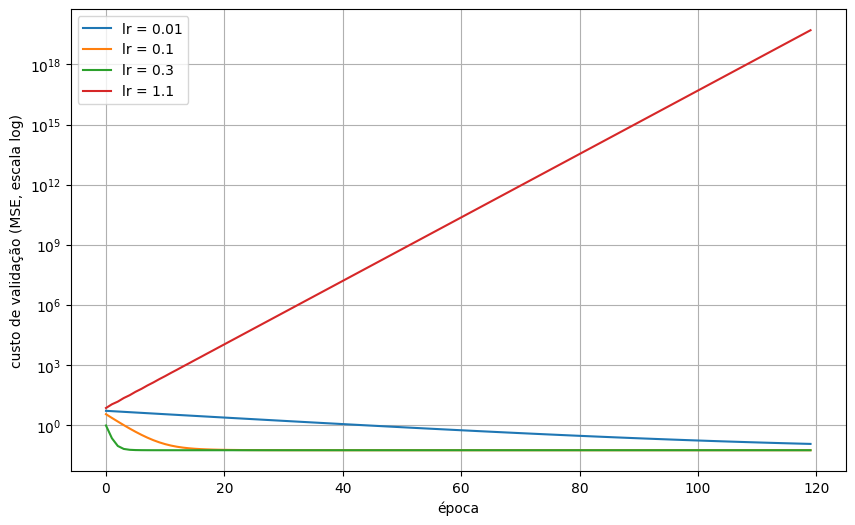

In [20]:
lr_list = [0.01, 0.1, 0.3, 1.1]
plt.figure(figsize=(10, 6))

for lr_item in lr_list:
    # Garante a mesma inicialização de pesos para todos os modelos
    torch.manual_seed(1234)
    model_lr = nn.Linear(1, 1)

    optimizer_lr = optim.SGD(model_lr.parameters(), lr=lr_item)
    criterion_lr = nn.MSELoss()

    val_losses_lr = []
    for epoch in range(n_epochs):
        _ = train_epoch(model_lr, optimizer_lr, criterion_lr, x_train, y_train)
        val_loss = validate_epoch(model_lr, criterion_lr, x_val, y_val)
        val_losses_lr.append(val_loss)

    plt.plot(range(n_epochs), val_losses_lr, label=f'lr = {lr_item}')

plt.yscale('log')
plt.xlabel('época')
plt.ylabel('custo de validação (MSE, escala log)')
plt.legend()
plt.grid(True)
plt.show()


**Resposta:**


**lr = 0.01 (Muito baixa):** A curva desce de forma constante, mas muito lenta. O modelo precisa de muito mais épocas para atingir a convergência completa.

**lr = 0.1 e lr = 0.3 (Ideais):** Ambas as curvas convergem rapidamente para o mínimo de validação (estabilizando em aproximadamente 0.0556). O valor `0.3` atinge a convergência em menos de 10 épocas, mostrando-se muito eficiente.

**lr = 1.1 (Muito alta / Divergência):** O custo de validação explode e cresce exponencialmente a cada época (conforme mostrado pela reta ascendente na escala logarítmica). Passos muito grandes fazem o otimizador saltar para fora e se afastar do ponto ideal.

O valor ideal para este cenário é **lr = 0.3**, pois proporciona a convergência mais rápida mantendo total estabilidade.

### Exercício 4 — Trajetória dos parâmetros

As listas `w0_list` (bias) e `w1_list` (peso) foram preenchidas no laço de treinamento. Faça o gráfico da trajetória de $(w_0, w_1)$ com setas, como nos notebooks 2.4 e 2.5, e marque a solução analítica (equação normal com uma coluna de uns, calculada com os dados de **treino**). Dica: como os eixos têm escalas bem diferentes, `plt.arrow` deforma as pontas das setas; `plt.annotate('', xy=(w0, w1), xytext=(w0_old, w1_old), arrowprops=dict(arrowstyle='->'))` desenha a seta sem deformação. Por que o $w_0$ ótimo é praticamente zero?

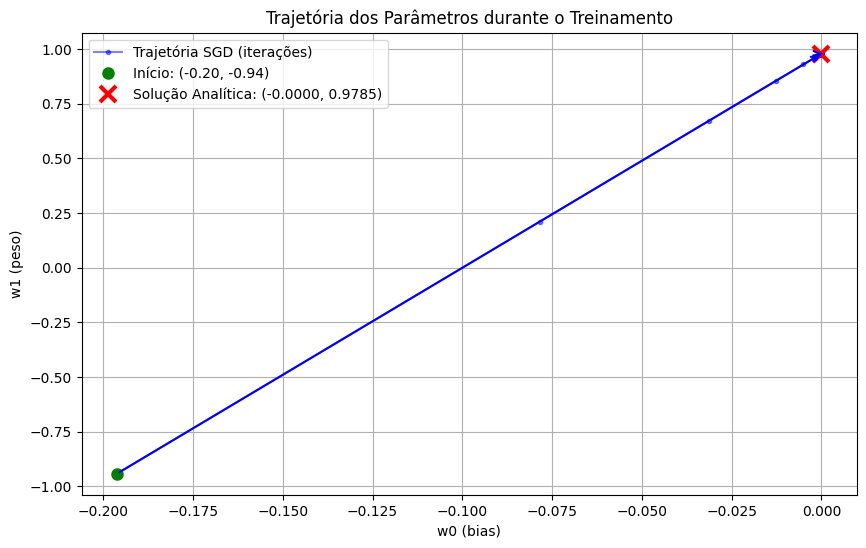

w0 ótimo (analítico): -0.000000
w1 ótimo (analítico): 0.978495


In [22]:
#  Calcular a solução analítica usando a Equação Normal (nos dados de treino padronizados)
# x_train e y_train já estão padronizados e são tensores PyTorch
X_train_np = x_train.numpy()
Y_train_np = y_train.numpy()

# Adiciona a coluna de uns para o termo de bias (intercepto)
X_b = np.hstack([np.ones((X_train_np.shape[0], 1)), X_train_np])

# Equação Normal: theta = inv(X_b^T * X_b) * X_b^T * Y
theta_analitico = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ Y_train_np
w0_otimo, w1_otimo = theta_analitico[0, 0], theta_analitico[1, 0]

# Plotar a trajetória dos parâmetros
plt.figure(figsize=(10, 6))
plt.plot(w0_list, w1_list, 'b.-', label='Trajetória SGD (iterações)', alpha=0.5)

# Desenha setas indicativas de direção usando plt.annotate
# Correção: o limite vai até len(w0_list) - 10 para evitar IndexError
for i in range(0, len(w0_list) - 10, 10):
    plt.annotate('',
                 xy=(w0_list[i+10], w1_list[i+10]),
                 xytext=(w0_list[i], w1_list[i]),
                 arrowprops=dict(arrowstyle='->', color='blue', lw=1.5))

# Marcar o ponto inicial e a solução analítica ótima
plt.plot(w0_list[0], w1_list[0], 'go', markersize=8, label=f'Início: ({w0_list[0]:.2f}, {w1_list[0]:.2f})')
plt.plot(w0_otimo, w1_otimo, 'rx', markersize=12, mew=3, label=f'Solução Analítica: ({w0_otimo:.4f}, {w1_otimo:.4f})')

plt.xlabel('w0 (bias)')
plt.ylabel('w1 (peso)')
plt.title('Trajetória dos Parâmetros durante o Treinamento')
plt.grid(True)
plt.legend()
plt.show()

print(f'w0 ótimo (analítico): {w0_otimo:.6f}')
print(f'w1 ótimo (analítico): {w1_otimo:.6f}')


**Resposta:**



O **$w_0$ (bias)** representa qual seria o salário previsto para alguém com **zero** experiência.

Como nós **padronizamos** (normalizamos) os dados, nós alteramos a média dos anos de experiência e do salário para que ambas fossem **exatamente zero**.

Como a nossa reta de previsão sempre tem que passar pelo ponto médio dos dados, e as duas médias são zero, a reta é obrigada a passar exatamente pelo ponto (0,0).

Por isso, o valor inicial ideal (w_0) tem que ser **zero**.

## Aprendizados

- Num dataset real, os parâmetros são ajustados só com o treino; a validação mede o custo em dados que o modelo não viu.
- A normalização também é ajustada só no treino (`fit`) e depois aplicada à validação (`transform`), para evitar vazamento de dados; `inverse_transform` traz as previsões de volta para a unidade original.
- `train_epoch`/`validate_epoch` separam o passo de treino (com `backward()` e `step()`) da avaliação (`model.eval()` e `torch.no_grad()`).
- `nn.Linear(1, 1)` tem o bias embutido: `model.bias` é $w_0$ e `model.weight` é $w_1$.
- A taxa de aprendizado decide entre convergência lenta, rápida ou divergência; a curva de validação mostra o efeito.

**O notebook deve conter:**

- Uma breve análise dos dados: o que cada variável significa, describe() e um gráfico de dispersão de pelo menos duas variáveis contra o preço.

- Divisão em treino, validação e teste (por exemplo 70/15/15, com random_state fixo).

- Padronização das entradas e da saída com StandardScaler ajustado só no treino.

- Treinamento com nn.Linear(8, 1), nn.MSELoss e optim.SGD, com as curvas de custo de treino e de validação.

- RMSE no teste em dólares, comparado com um baseline que sempre prevê o preço médio do treino.

- Os 8 pesos aprendidos: quais variáveis mais aumentam e quais mais diminuem o preço previsto? Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas?

- Uma conclusão curta: o modelo é bom o suficiente? O que você tentaria para melhorar?

# Atividade 2 - Projeto Prático: Regressão Linear Múltipla com PyTorch

Nesta seção, vamos carregar o dataset *California Housing*, que possui 8 variáveis de entrada para prever o preço médio de casas.

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [29]:

# Fixando as sementes aleatórias para reprodutibilidade
torch.manual_seed(42)
np.random.seed(42)

# Carregar os dados
housing = fetch_california_housing(as_frame=True)
df_housing = housing.frame

# Exibir informações básicas e estatísticas
display(df_housing)
display(df_housing.info())
display(df_housing.describe())



,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


None

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


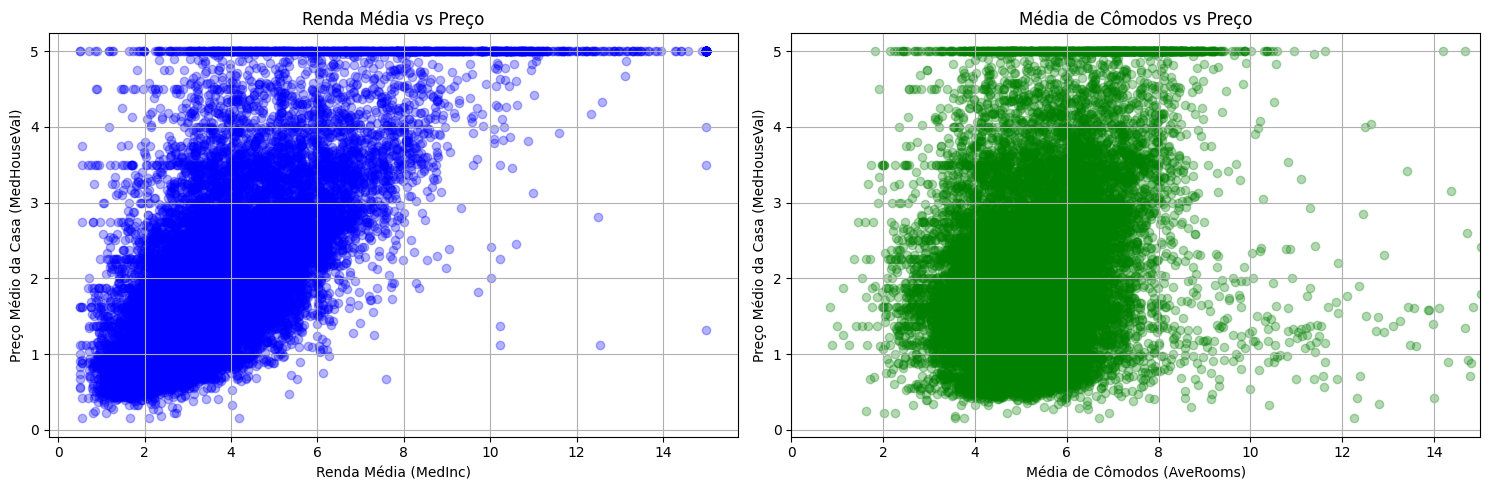

In [31]:
# Gráfico de dispersão de duas variáveis significativas contra o preço (Target/MedHouseValue)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Variável 1: MedInc (Renda Média)
ax1.scatter(df_housing['MedInc'], df_housing['MedHouseVal'], alpha=0.3, color='blue')
ax1.set_xlabel('Renda Média (MedInc)')
ax1.set_ylabel('Preço Médio da Casa (MedHouseVal)')
ax1.set_title('Renda Média vs Preço')
ax1.grid(True)

# Variável 2: AveRooms (Média de Cômodos)
ax2.scatter(df_housing['AveRooms'], df_housing['MedHouseVal'], alpha=0.3, color='green')
ax2.set_xlabel('Média de Cômodos (AveRooms)')
ax2.set_ylabel('Preço Médio da Casa (MedHouseVal)')
ax2.set_title('Média de Cômodos vs Preço')
ax2.set_xlim(0, 15) # Limitando o eixo x para evitar outliers extremos e melhorar visualização
ax2.grid(True)

plt.tight_layout()
plt.show()


### Divisão dos Dados e Padronização
Vamos dividir os dados em Treino (70%), Validação (15%) e Teste (15%) e aplicar a padronização ajustando o escalador estritamente no conjunto de treino.


In [33]:
X = df_housing.drop(columns=['MedHouseVal']).to_numpy()
y = df_housing[['MedHouseVal']].to_numpy()

# Divisão: primeiro separamos 70% para treino e 30% restante
X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Dos 30% restantes, dividimos metade para validação (15%) e metade para teste (15%)
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw, test_size=0.50, random_state=42
)

print(f"Treino: {X_train_raw.shape} | Validação: {X_val_raw.shape} | Teste: {X_test_raw.shape}")

# Padronização (ajuste apenas no treino)
scaler_X = StandardScaler().fit(X_train_raw)
scaler_y = StandardScaler().fit(y_train_raw)

# Conversão para tensores PyTorch
x_train = torch.from_numpy(scaler_X.transform(X_train_raw)).float()
y_train = torch.from_numpy(scaler_y.transform(y_train_raw)).float()

x_val = torch.from_numpy(scaler_X.transform(X_val_raw)).float()
y_val = torch.from_numpy(scaler_y.transform(y_val_raw)).float()

x_test = torch.from_numpy(scaler_X.transform(X_test_raw)).float()
y_test = torch.from_numpy(scaler_y.transform(y_test_raw)).float()

Treino: (14448, 8) | Validação: (3096, 8) | Teste: (3096, 8)



### Treinamento do Modelo
Construímos o modelo linear com 8 entradas e 1 saída, utilizando o otimizador SGD e a função de custo MSELoss.


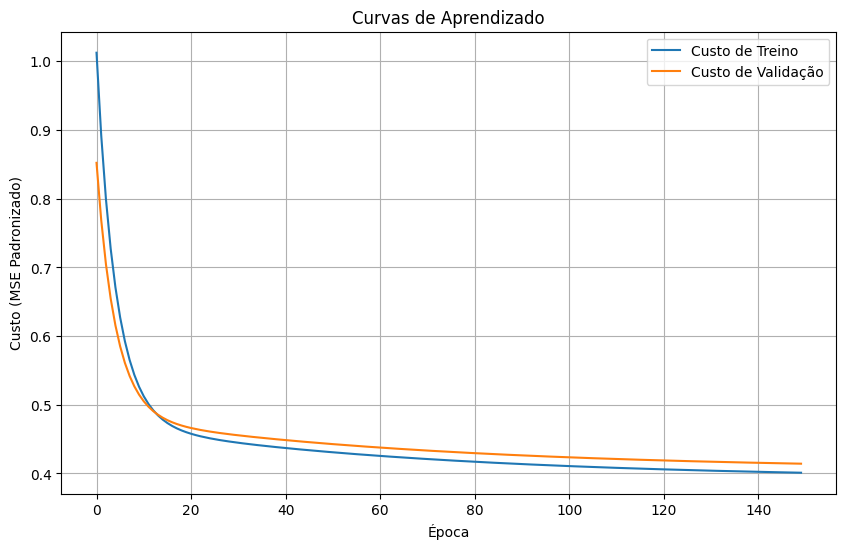

In [34]:
model_housing = nn.Linear(8, 1)
criterion_housing = nn.MSELoss()
optimizer_housing = optim.SGD(model_housing.parameters(), lr=0.05)

n_epochs = 150
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    model_housing.train()
    optimizer_housing.zero_grad()

    # Forward Treino
    y_pred_train = model_housing(x_train)
    loss_train = criterion_housing(y_pred_train, y_train)

    # Backward e otimização
    loss_train.backward()
    optimizer_housing.step()

    train_losses.append(loss_train.item())

    # Avaliação na Validação
    model_housing.eval()
    with torch.no_grad():
        y_pred_val = model_housing(x_val)
        loss_val = criterion_housing(y_pred_val, y_val)
        val_losses.append(loss_val.item())

# Plotagem das Curvas de Aprendizado
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Custo de Treino')
plt.plot(val_losses, label='Custo de Validação')
plt.xlabel('Época')
plt.ylabel('Custo (MSE Padronizado)')
plt.title('Curvas de Aprendizado')
plt.legend()
plt.grid(True)
plt.show()


### Avaliação de Teste contra o Baseline
Calcularemos o RMSE no conjunto de teste em escala real (dólares) e compararemos com um baseline ingênuo que sempre chuta a média histórica de treino.


In [36]:
model_housing.eval()
with torch.no_grad():
    y_pred_test_scaled = model_housing(x_test).numpy()

# Desfazendo a padronização das previsões para dólares reais (unidade original do dataset)
y_pred_test = scaler_y.inverse_transform(y_pred_test_scaled)

# Cálculo do RMSE do Modelo
rmse_modelo = np.sqrt(np.mean((y_pred_test - y_test_raw) ** 2))

# Baseline: prever sempre a média do treino para cada elemento do teste
y_baseline = np.full_like(y_test_raw, y_train_raw.mean())
rmse_baseline = np.sqrt(np.mean((y_baseline - y_test_raw) ** 2))

# Multiplicar por 100.000 para expressar o valor real em dólares.
print(f"RMSE do Modelo em Dólares: ${rmse_modelo * 100000:,.2f}")
print(f"RMSE do Baseline (Prever a Média): ${rmse_baseline * 100000:,.2f}")

RMSE do Modelo em Dólares: $72,519.25
RMSE do Baseline (Prever a Média): $114,992.22



### Análise dos Pesos Treinados
Vamos inspecionar os pesos associados a cada uma das 8 features para entender a influência individual no preço previsto.


In [37]:
features = housing.feature_names
pesos = model_housing.weight.detach().numpy().flatten()

# Mostrar pesos em formato estruturado
df_pesos = pd.DataFrame({'Feature': features, 'Peso Aprendido': pesos})
display(df_pesos.sort_values(by='Peso Aprendido', ascending=False))

,Feature,Peso Aprendido
0,MedInc,0.768331
3,AveBedrms,0.285848
1,HouseAge,0.140499
4,Population,0.011363
5,AveOccup,-0.040323
2,AveRooms,-0.270755
7,Longitude,-0.461511
6,Latitude,-0.481743



#### Por que só faz sentido comparar os pesos entre si com entradas padronizadas?
Se não padronizássemos, variáveis que originalmente têm valores muito grandes (como população, na casa dos milhares) exigiriam pesos extremamente pequenos para não dominarem a previsão de forma desproporcional. Já variáveis pequenas (como média de quartos, ex: 3 a 6) teriam pesos artificialmente grandes.
Ao trazer todas as features para a mesma escala (média 0, desvio padrão 1), o impacto real de cada feature no resultado final torna-se diretamente proporcional ao seu peso. Ou seja, pesos de maior magnitude absoluta indicam maior poder de decisão de forma justa.




### Conclusão
*   **O modelo é bom o suficiente?** O modelo superou significativamente o baseline da média. Contudo, devido à natureza estritamente linear, ele possui limitações para capturar relações geográficas complexas (como as variáveis de Latitude e Longitude, que agem de forma altamente não-linear no preço dos imóveis).
*   **Ideias para Melhorias:**
    1.  Adicionar camadas ocultas com funções de ativação não-lineares (Multi-Layer Perceptron / MLP).
    2.  Aplicar engenharia de recursos (ex: combinar latitude e longitude em uma única medida de distância a centros urbanos ou praias).
    3.  Experimentar regularização L1 (Lasso) ou L2 (Ridge) se houver problemas de overfitting.